05 : Develop a Random Forest classification model to predict the forest cover type based on cartographic
variables. Handle missing data and perform feature scaling. Evaluate the model using accuracy, precision,
recall, and F1 score. Dataset: Forest Cover Type Dataset (UCI).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [4]:
df = pd.read_csv('covtype.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [5]:
if df.isnull().sum().sum() > 0 :
    print("Missing Values Found !!")
    print(df.isnull().sum())
else :
    print("No Missing Values Found !!")

No Missing Values Found !!


In [7]:
df.columns

Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1',
       'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4',
       'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5',
       'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10',
       'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14',
       'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18',
       'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22',
       'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26',
       'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30',
       'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34',
       'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38',
       'Soil_Type39', 'Soil_Type40

In [9]:
x = df.drop(['Cover_Type'], axis=1)
y = df['Cover_Type']

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [13]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [15]:
model = RandomForestClassifier(
    n_estimators=100, max_depth=10,
    n_jobs=-1, criterion='gini',
    random_state=42
)

In [16]:
model.fit(x_train, y_train)
print("Model Training Completed !!")

Model Training Completed !!


In [17]:
y_pred = model.predict(x_test)
print(y_pred)

[1 2 2 ... 2 2 7]


In [18]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy : ", acc*100, "%")

Accuracy :  75.16329182551225 %


In [22]:
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
print("Precision :", precision*100, "%")

Precision : 74.46099226838562 %


In [23]:
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
print("Recall :", recall*100, "%")

Recall : 75.16329182551225 %


In [26]:
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print("F1 :", f1*100, "%")

F1 : 73.69161329575157 %


In [28]:
cr = classification_report(y_test, y_pred, zero_division=0)
print("Classification Report :\n", cr)

Classification Report :
               precision    recall  f1-score   support

           1       0.74      0.74      0.74     42557
           2       0.76      0.83      0.79     56500
           3       0.72      0.85      0.78      7121
           4       0.90      0.34      0.50       526
           5       0.00      0.00      0.00      1995
           6       0.84      0.14      0.25      3489
           7       0.95      0.53      0.68      4015

    accuracy                           0.75    116203
   macro avg       0.70      0.49      0.53    116203
weighted avg       0.74      0.75      0.74    116203



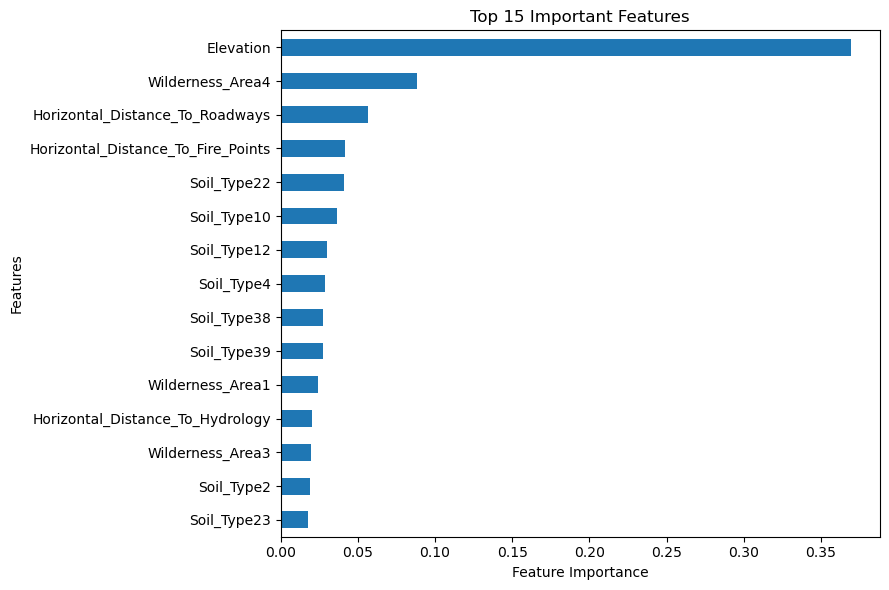

In [29]:
importance = pd.Series(
    model.feature_importances_,
    index=x.columns
)

importance = importance.sort_values(ascending=False).head(15)

importance.sort_values().plot(kind="barh", figsize=(9, 6))

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()


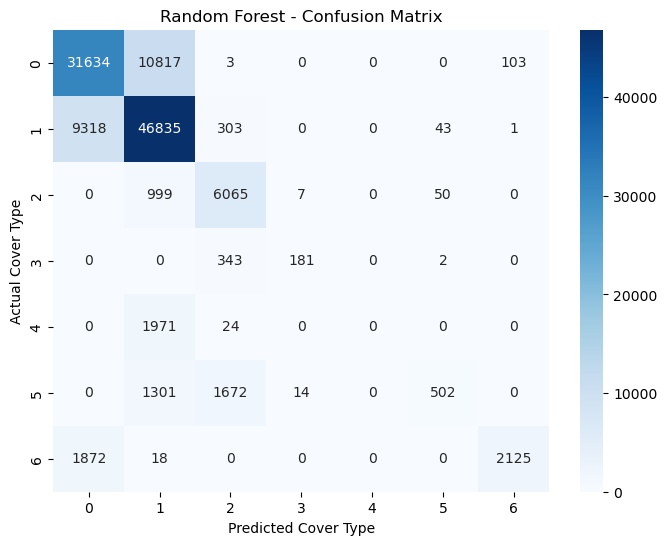

In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Cover Type")
plt.ylabel("Actual Cover Type")
plt.title("Random Forest - Confusion Matrix")
plt.show()
